In [1]:
from Hao_Harris_A1 import convert2grey, structure_tensor, harris_response, harris_classic, log_normalized, nms_2d, rotate_matrix,guassian_blur, repeatability

In [2]:
import time
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from dataclasses import dataclass

IMAGE_PATH = "chess.jpg" 
MAX_SIDE = 700            
K = 0.05                   
EPS = 1.5                  
N_POINTS = 300             
MARGIN = 10
SCALE_FACTORS = np.array([1.0, 0.8, 0.67, 0.5, 0.4, 0.33, 0.25])
SWEEP_FACTORS = np.array([0.67, 0.5, 0.33])

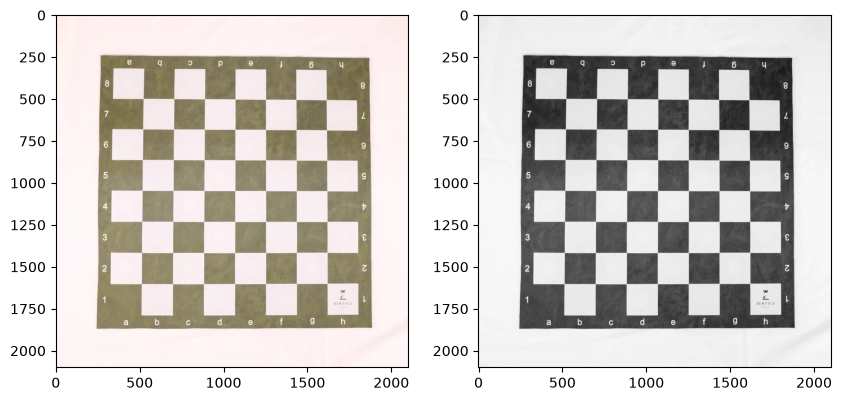

In [3]:
img = cv.imread(IMAGE_PATH)
grey = convert2grey(img)
ax = plt.subplots(1, 2, figsize = (10, 10))[1]
ax[0].imshow(img)
ax[1].imshow(grey, cmap = 'grey')
plt.show()

In [4]:
def resize_matrix(fx, fy):
    return np.array([[fx, 0.0, 0.5 * (fx - 1)],
                     [0.0, fy, 0.5 * (fy - 1)]])

def keep_strongest(points, n=N_POINTS):
    """Giữ n điểm có response lớn nhất; n=None thì giữ tất cả."""
    if n is None:
        return points
    return points[np.argsort(points[:, 3])[::-1][:n]]

def apply_affine(points_rc, M):
    """[x', y']ᵀ = M · [x, y, 1]ᵀ, với (x, y) = (col, row). -> (N, 2) dạng (row, col)."""
    xy1 = np.column_stack((points_rc[:, 1], points_rc[:, 0], np.ones(len(points_rc))))
    return (xy1 @ M.T)[:, [1, 0]]


def repeatability_vs_scale(detector, img, factors=SCALE_FACTORS, eps=EPS, n_points=N_POINTS):
    """Đường cong rep(f), với ảnh B = cv.resize(A, f). -> mảng cùng độ dài với factors."""
    pts_a = keep_strongest(detector.detect(img), n_points)
    reps = []
    for f in factors:
        small = cv.resize(img, None, fx=f, fy=f, interpolation=cv.INTER_AREA)
        pts_b = keep_strongest(detector.detect(small), n_points)
        reps.append(repeatability(pts_a, pts_b, resize_matrix(f, f), img.shape, small.shape, eps))
    return np.array(reps) 

In [5]:
fake = np.array([[50, 60, 2.0, 1.0], [80, 90, 2.0, 3.0]])
identity = np.array([[1.0, 0, 0], [0, 1, 0]])
print("rep(đồng nhất) =", repeatability(fake, fake, identity, (200, 200), (200, 200)))

# Kiểm tra 2: resize_matrix phải dự đoán đúng vị trí đỉnh sau khi thu nhỏ
probe = np.zeros((200, 200), np.float32); probe[100, 60] = 1
probe = guassian_blur(probe, 4)
small = cv.resize(probe, None, fx=0.5, fy=0.5, interpolation=cv.INTER_AREA)
print("Đỉnh thật:", np.unravel_index(small.argmax(), small.shape),
      "| dự đoán:", apply_affine(np.array([[100.0, 60.0]]), resize_matrix(0.5, 0.5)))

rep(đồng nhất) = 1.0
Đỉnh thật: (np.int64(50), np.int64(30)) | dự đoán: [[49.75 29.75]]
